# Plot Style Guide

A self-contained notebook for making consistent research figures from arbitrary data. It distills the recurring choices in `final_plots.ipynb`: muted colors, light-gray axes, strong labels, compact legends, direct annotations, uncertainty displays, and publication-ready PDF/PNG export.

**Working rule:** use color for series or metric identity, hatching or line style for state, and annotations only for values the reader should compare.

In [82]:
# Import plotting libraries
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import seaborn as sns

print(f"Matplotlib {plt.matplotlib.__version__} | Seaborn {sns.__version__} | pandas {pd.__version__}")

Matplotlib 3.9.4 | Seaborn 0.13.2 | pandas 2.3.3


## 1-3. Imports, Global Style, and Design Tokens

Keep visual decisions centralized. The palette is categorical rather than sequential; gray is reserved for baselines and reference marks. Figures use a soft panel background, dark left/bottom spines, subtle horizontal grids, and bold display labels.

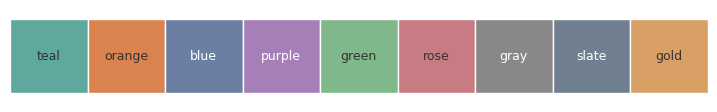

In [83]:
# Configure global plot style
COLORS = {
    "teal": "#5fa89d",
    "orange": "#d9844f",
    "blue": "#6b7fa3",
    "purple": "#a67fb8",
    "green": "#7fb88a",
    "rose": "#c97b84",
    "gray": "#888888",
    "slate": "#708090",
    "gold": "#d9a066",
    "ink": "#333333",
}
PALETTE = [COLORS[name] for name in ("teal", "orange", "blue", "purple", "green")]
METRIC_COLORS = {
    "G-Mean": COLORS["slate"],
    "Recall": "#6a9fb5",
    "FPR": COLORS["rose"],
    "Influence Rate": COLORS["gold"],
}
PANEL_BACKGROUND = "#f5f5f5"
GRID_COLOR = "#b5b5b5"
GRID_ALPHA = 0.60
GRID_LINEWIDTH = 0.9
OUTPUT_DIR = Path("style_guide_figures")

FONT = {"title": 15, "panel_title": 13, "label": 13, "tick": 11, "annotation": 10}
LINE_WIDTH = 2.7
MARKER_SIZE = 7
EXPORT_DPI = 300

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "font.family": "DejaVu Sans",
    "font.size": FONT["tick"],
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID_COLOR,
    "grid.alpha": GRID_ALPHA,
    "grid.linewidth": GRID_LINEWIDTH,
    "grid.linestyle": "--",
    "lines.linewidth": LINE_WIDTH,
    "savefig.dpi": EXPORT_DPI,
})

# Palette swatches
fig, ax = plt.subplots(figsize=(9, 1.2))
for index, (name, color) in enumerate(list(COLORS.items())[:-1]):
    ax.barh(0, 1, left=index, color=color)
    ax.text(index + 0.5, 0, name, ha="center", va="center", fontsize=9,
            color="white" if name in {"blue", "purple", "gray", "slate"} else COLORS["ink"])
ax.set(xlim=(0, len(COLORS) - 1), ylim=(-0.5, 0.5))
ax.axis("off")
plt.show()

## 4. Synthetic Example Data

The examples below are deterministic and project-independent. Replace these frames with real data while preserving the tidy column contracts.

In [84]:
# Generate synthetic example data
rng = np.random.default_rng(42)
rounds = np.arange(7)

line_rows = []
for series, start, gain in [
    ("Reasoning", 0.58, 0.30),
    ("Outcome-only", 0.62, 0.08),
    ("Reference model", 0.52, 0.18),
]:
    mean = start + gain * (1 - np.exp(-rounds / 2.4)) + rng.normal(0, 0.008, len(rounds))
    half_width = np.linspace(0.045, 0.025, len(rounds))
    line_rows.extend({
        "round": round_num,
        "series": series,
        "mean": value,
        "ci_low": value - half_width[index],
        "ci_high": value + half_width[index],
    } for index, (round_num, value) in enumerate(zip(rounds, mean)))
line_df = pd.DataFrame(line_rows)

facet_rows = []
for dataset_index, dataset in enumerate(["SNLI", "ETHICS", "MMLU-Pro"]):
    for series_index, series in enumerate(["Reasoning", "Outcome-only"]):
        base = 0.54 + 0.025 * dataset_index + 0.035 * series_index
        gain = 0.24 - 0.16 * series_index
        values = base + gain * (1 - np.exp(-rounds / 2.2)) + rng.normal(0, 0.008, len(rounds))
        facet_rows.extend({"dataset": dataset, "round": round_num, "series": series, "value": value}
                          for round_num, value in zip(rounds, values))
facet_df = pd.DataFrame(facet_rows)

experiments = ["Small", "Medium", "Large"]
metrics = ["G-Mean", "Recall", "FPR", "Influence Rate"]
bar_rows = []
for exp_index, experiment in enumerate(experiments):
    before_values = [0.48 + 0.04 * exp_index, 0.55 + 0.03 * exp_index, 0.34 - 0.02 * exp_index, 0.42]
    after_values = [0.66 + 0.05 * exp_index, 0.76 + 0.03 * exp_index, 0.23 - 0.02 * exp_index, 0.43]
    for metric, before, after in zip(metrics, before_values, after_values):
        for state, value in [("Before", before), ("After", after)]:
            bar_rows.append({
                "experiment": experiment,
                "metric": metric,
                "state": state,
                "value": value,
                "error": 0.025 + 0.005 * rng.random(),
            })
bar_df = pd.DataFrame(bar_rows)

scaling_df = pd.DataFrame({
    "training_examples": [50, 125, 500, 1000, 2000],
    "mean": [0.47, 0.57, 0.69, 0.76, 0.80],
    "ci_low": [0.41, 0.52, 0.65, 0.72, 0.77],
    "ci_high": [0.53, 0.62, 0.73, 0.80, 0.83],
})

line_df.head()

,round,series,mean,ci_low,ci_high
0,0,Reasoning,0.582438,0.537438,0.627438
1,1,Reasoning,0.673908,0.632241,0.715575
2,2,Reasoning,0.755624,0.717291,0.793957
3,3,Reasoning,0.801573,0.766573,0.836573
4,4,Reasoning,0.807729,0.776062,0.839396


## 5, 11, 12. Shared Styling, Legends, and Export

These helpers are the stable core. Plot-specific functions should draw marks, then delegate axes, legends, and saving here.

In [85]:
def require_columns(df, columns):
    """Raise a clear error when a plotting data contract is incomplete."""
    missing = sorted(set(columns) - set(df.columns))
    if missing:
        raise ValueError(f"Missing required columns: {missing}")
    if df.empty:
        raise ValueError("Plot data must not be empty")


def style_axis(ax, *, title=None, xlabel=None, ylabel=None, ylim=None,
               integer_x=False, percent_y=False):
    """Apply the shared paper-figure axis style."""
    ax.set_facecolor(PANEL_BACKGROUND)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(COLORS["ink"])
        ax.spines[side].set_linewidth(1.4)
    ax.grid(True, axis="y", linestyle="--", color=GRID_COLOR,
            linewidth=GRID_LINEWIDTH, alpha=GRID_ALPHA)
    ax.grid(False, axis="x")
    ax.tick_params(axis="both", labelsize=FONT["tick"], length=3, pad=3)
    if title:
        ax.set_title(title, fontsize=FONT["title"], fontweight="bold", pad=10)
    ax.set_xlabel(xlabel or "", fontsize=FONT["label"], fontweight="bold")
    ax.set_ylabel(ylabel or "", fontsize=FONT["label"], fontweight="bold")
    if ylim is not None:
        ax.set_ylim(*ylim)
    if integer_x:
        ticks = sorted(set(np.asarray(ax.get_xticks()).astype(int)))
        if ticks:
            ax.set_xticks(ticks)
    if percent_y:
        from matplotlib.ticker import PercentFormatter
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    return ax


def pad_y_axis(ax, values, fraction=0.16, floor=None, ceiling=None):
    """Add stable vertical breathing room around finite values."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return ax
    low, high = values.min(), values.max()
    margin = max((high - low) * fraction, 0.03 * max(abs(high), 1))
    lower = low - margin if floor is None else max(floor, low - margin)
    upper = high + margin if ceiling is None else min(ceiling, high + margin)
    ax.set_ylim(lower, upper)
    return ax


def add_shared_legend(fig, handles, labels, *, location="bottom", ncol=None, bold=True):
    """Place a compact figure-level legend below or to the right."""
    if location not in {"bottom", "right"}:
        raise ValueError("location must be 'bottom' or 'right'")
    properties = {"size": 12, "weight": "bold" if bold else "normal"}
    if location == "right":
        return fig.legend(handles, labels, frameon=False, loc="center left",
                          bbox_to_anchor=(1.0, 0.5), ncol=ncol or 1, prop=properties)
    return fig.legend(handles, labels, frameon=False, loc="upper center",
                      bbox_to_anchor=(0.5, 0.02), ncol=ncol or len(labels), prop=properties)


def save_figure(fig, name, *, output_dir=OUTPUT_DIR, formats=("pdf", "png"), dpi=EXPORT_DPI):
    """Save vector and raster copies with consistent publication settings."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    paths = []
    for suffix in formats:
        path = output_dir / f"{name}.{suffix}"
        fig.savefig(path, bbox_inches="tight", dpi=dpi, facecolor="white", edgecolor="none")
        paths.append(path)
    return paths

## 6-7. Styled Lines and Uncertainty

Use ribbons for compact uncertainty, error bars when exact intervals matter, and boundary lines only when the bounds themselves are part of the comparison.

In [86]:
def plot_lines(df, *, x, y, series, ci_low=None, ci_high=None, ci_style="ribbon",
               title=None, xlabel=None, ylabel=None, ylim=None, scale=100,
               annotate=False, ax=None, palette=PALETTE):
    """Plot multiple series with optional confidence intervals."""
    required = [x, y, series]
    if ci_low or ci_high:
        if not (ci_low and ci_high):
            raise ValueError("ci_low and ci_high must be provided together")
        required += [ci_low, ci_high]
    require_columns(df, required)
    if ci_style not in {"ribbon", "lines", "ribbon+lines", "errorbar"}:
        raise ValueError("Invalid ci_style")

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5))
    series_order = list(pd.unique(df[series]))

    for index, label in enumerate(series_order):
        group = df[df[series] == label].sort_values(x)
        color = palette[index % len(palette)]
        x_values = group[x].to_numpy()
        y_values = group[y].to_numpy() * scale
        low = group[ci_low].to_numpy() * scale if ci_low else None
        high = group[ci_high].to_numpy() * scale if ci_high else None

        if low is not None and ci_style in {"ribbon", "ribbon+lines"}:
            ax.fill_between(x_values, low, high, color=color, alpha=0.16, linewidth=0)
        if low is not None and ci_style in {"lines", "ribbon+lines"}:
            ax.plot(x_values, low, color=color, linestyle="--", linewidth=1.2, alpha=0.45)
            ax.plot(x_values, high, color=color, linestyle="--", linewidth=1.2, alpha=0.45)
        ax.plot(x_values, y_values, color=color, marker="o", markersize=MARKER_SIZE,
                linewidth=LINE_WIDTH, label=label, zorder=3)
        if low is not None and ci_style == "errorbar":
            ax.errorbar(x_values, y_values, yerr=[y_values - low, high - y_values],
                        fmt="none", ecolor=color, capsize=3, elinewidth=1.3, alpha=0.75)
        if annotate:
            for x_value, y_value in zip(x_values, y_values):
                ax.annotate(f"{y_value:.1f}", (x_value, y_value), xytext=(0, 7),
                            textcoords="offset points", ha="center", fontsize=FONT["annotation"], alpha=0.8)

    style_axis(ax, title=title, xlabel=xlabel, ylabel=ylabel, ylim=ylim,
               integer_x=np.issubdtype(df[x].dtype, np.integer), percent_y=scale == 100)
    if ylim is None:
        pad_y_axis(ax, df[y] * scale, floor=0 if scale == 100 else None, ceiling=100 if scale == 100 else None)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14),
              ncol=len(series_order), prop={"size": 11, "weight": "bold"})
    return ax

## 8-10. Facets, Bars, Baselines, and Deltas

Use facets when axes share a comparison grammar. Use bars for discrete conditions, keep paired states touching, and separate experiment groups with whitespace. Baselines should be gray and dashed; delta annotations should be sparse and signed.

In [87]:
def add_delta_bracket(ax, x, y_first, y_second, *, text=None, color=COLORS["rose"], side="right"):
    """Draw a compact bracket between two values at one x position."""
    if side not in {"left", "right"}:
        raise ValueError("side must be 'left' or 'right'")
    direction = 1 if side == "right" else -1
    bracket_x = x + 0.12 * direction
    cap = 0.10 * direction
    low, high = sorted([y_first, y_second])
    ax.plot([bracket_x, bracket_x], [low, high], color=color, linewidth=1.5, zorder=4)
    ax.plot([bracket_x, bracket_x + cap], [low, low], color=color, linewidth=1.5, zorder=4)
    ax.plot([bracket_x, bracket_x + cap], [high, high], color=color, linewidth=1.5, zorder=4)
    label = text or f"Δ={y_first - y_second:+.1f}"
    ax.annotate(label, (bracket_x + 1.5 * cap, (low + high) / 2),
                ha="left" if side == "right" else "right", va="center",
                fontsize=FONT["annotation"], fontweight="bold", color=color)
    return ax


def plot_facets(df, *, facet, x, y, series, ncols=3, title=None,
                xlabel=None, ylabel=None, ylims=None, scale=100):
    """Create a configurable line-chart grid with one shared legend."""
    require_columns(df, [facet, x, y, series])
    facets = list(pd.unique(df[facet]))
    nrows = int(np.ceil(len(facets) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
    flat_axes = axes.ravel()
    handles = []
    labels = []

    for index, facet_value in enumerate(facets):
        ax = flat_axes[index]
        group = df[df[facet] == facet_value]
        for series_index, series_value in enumerate(pd.unique(group[series])):
            series_data = group[group[series] == series_value].sort_values(x)
            line, = ax.plot(series_data[x], series_data[y] * scale, marker="o",
                            color=PALETTE[series_index], label=series_value)
            if index == 0:
                handles.append(line)
                labels.append(series_value)
        facet_ylim = ylims[index] if ylims is not None else None
        style_axis(ax, title=str(facet_value), xlabel="", ylabel=ylabel if index % ncols == 0 else "",
                   ylim=facet_ylim, integer_x=True, percent_y=scale == 100)
        if facet_ylim is None:
            pad_y_axis(ax, group[y] * scale, floor=0, ceiling=100 if scale == 100 else None)

    for ax in flat_axes[len(facets):]:
        ax.set_visible(False)
    if title:
        fig.suptitle(title, fontsize=20, fontweight="bold", y=1.02)
    add_shared_legend(fig, handles, labels, location="bottom")
    fig.supxlabel(xlabel or "", fontsize=FONT["label"], fontweight="bold", y=0.04)
    fig.align_ylabels()
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    return fig, flat_axes[:len(facets)]

In [88]:
def plot_grouped_bars(df, *, category, group, value, error=None, title=None,
                      ylabel=None, baseline=None, scale=100, ax=None, annotate=True):
    """Plot grouped bars with optional error bars and a reference baseline."""
    required = [category, group, value] + ([error] if error else [])
    require_columns(df, required)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5))
    categories = list(pd.unique(df[category]))
    groups = list(pd.unique(df[group]))
    x_positions = np.arange(len(categories))
    width = 0.72 / len(groups)

    for group_index, group_value in enumerate(groups):
        group_df = df[df[group] == group_value].set_index(category).reindex(categories)
        values = group_df[value].to_numpy() * scale
        errors = group_df[error].to_numpy() * scale if error else None
        offset = (group_index - (len(groups) - 1) / 2) * width
        bars = ax.bar(x_positions + offset, values, width, color=PALETTE[group_index],
                      edgecolor=COLORS["ink"], linewidth=0.7, label=group_value,
                      yerr=errors, capsize=3 if error else 0,
                      error_kw={"linewidth": 1.2, "alpha": 0.7})
        if annotate:
            for bar, value_number, error_number in zip(bars, values, errors if errors is not None else np.zeros(len(values))):
                ax.annotate(f"{value_number:.1f}",
                            (bar.get_x() + bar.get_width() / 2, value_number + error_number),
                            xytext=(0, 4), textcoords="offset points", ha="center",
                            fontsize=FONT["annotation"], alpha=0.8)

    if baseline is not None:
        ax.axhline(baseline * scale, color=COLORS["gray"], linestyle=(0, (8, 4)),
                   linewidth=1.8, label="Baseline")
    ax.set_xticks(x_positions, categories, fontweight="bold")
    style_axis(ax, title=title, ylabel=ylabel, percent_y=scale == 100)
    pad_y_axis(ax, df[value] * scale, floor=0, ceiling=None)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14),
              ncol=len(groups) + int(baseline is not None), prop={"size": 11, "weight": "bold"})
    return ax


def plot_metric_panels(df, *, experiment="experiment", metric="metric", state="state",
                       value="value", error="error", title=None, scale=100):
    """Plot one before/after bar panel per metric."""
    require_columns(df, [experiment, metric, state, value, error])
    metric_order = list(pd.unique(df[metric]))
    experiment_order = list(pd.unique(df[experiment]))
    fig, axes = plt.subplots(1, len(metric_order), figsize=(4.2 * len(metric_order), 5), sharey=True)
    axes = np.atleast_1d(axes)
    bar_width = 0.34
    x_positions = np.arange(len(experiment_order))

    for ax, metric_name in zip(axes, metric_order):
        metric_df = df[df[metric] == metric_name]
        color = METRIC_COLORS.get(metric_name, COLORS["gray"])
        for state_index, state_name in enumerate(["Before", "After"]):
            state_df = metric_df[metric_df[state] == state_name].set_index(experiment).reindex(experiment_order)
            values = state_df[value].to_numpy() * scale
            errors = state_df[error].to_numpy() * scale
            positions = x_positions + (state_index - 0.5) * bar_width
            bars = ax.bar(positions, values, bar_width, color=color, edgecolor=COLORS["ink"],
                          linewidth=0.8, hatch="///" if state_name == "Before" else None,
                          alpha=0.72 if state_name == "Before" else 1.0,
                          yerr=errors, capsize=3)
            for bar, value_number, error_number in zip(bars, values, errors):
                ax.annotate(f"{value_number:.0f}",
                            (bar.get_x() + bar.get_width() / 2, value_number + error_number),
                            xytext=(0, 3), textcoords="offset points", ha="center",
                            fontsize=FONT["annotation"], fontweight="bold" if state_name == "After" else "normal")
        ax.set_xticks(x_positions, experiment_order, fontweight="bold")
        style_axis(ax, title=metric_name, percent_y=scale == 100, ylim=(0, 108))

    legend_handles = [
        Patch(facecolor="white", edgecolor=COLORS["ink"], hatch="///", label="Before"),
        Patch(facecolor="white", edgecolor=COLORS["ink"], label="After"),
    ]
    if title:
        fig.suptitle(title, fontsize=20, fontweight="bold", y=1.0)
    add_shared_legend(fig, legend_handles, ["Before", "After"], location="bottom", ncol=2)
    fig.tight_layout(rect=(0, 0.08, 1, 0.95))
    return fig, axes

## 13. Plot Style Reference Gallery

These are copy-and-modify recipes. Each example returns Matplotlib objects so titles, annotations, and export can still be adjusted afterward.

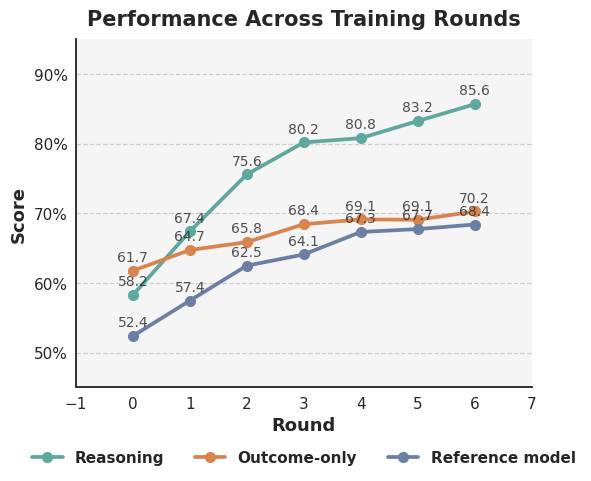

In [89]:
# Line chart with direct values and a compact legend
fig, ax = plt.subplots(figsize=(6, 5))
plot_lines(
    line_df,
    x="round", y="mean", series="series",
    title="Performance Across Training Rounds",
    xlabel="Round", ylabel="Score",
    ylim=(45, 95), annotate=True, ax=ax,
)
fig.tight_layout()
plt.show()

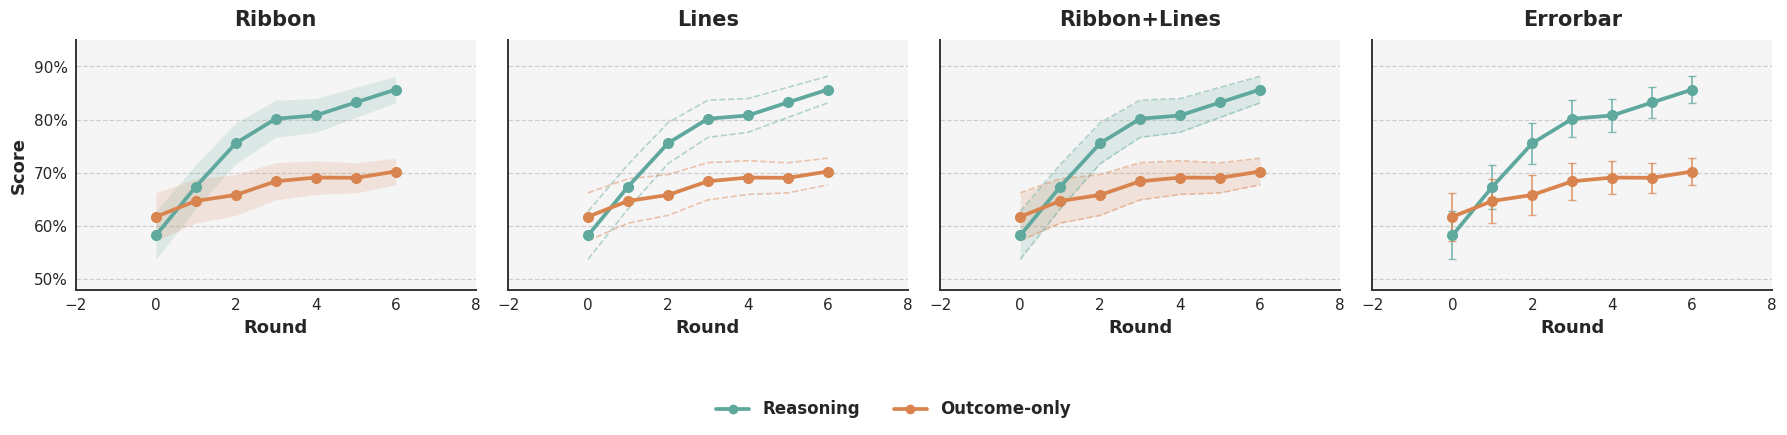

In [90]:
# Confidence interval style comparison
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, ci_style in zip(axes, ["ribbon", "lines", "ribbon+lines", "errorbar"]):
    plot_lines(
        line_df[line_df["series"].isin(["Reasoning", "Outcome-only"])],
        x="round", y="mean", series="series", ci_low="ci_low", ci_high="ci_high",
        ci_style=ci_style, title=ci_style.title(), xlabel="Round",
        ylabel="Score" if ax is axes[0] else "", ylim=(48, 95), ax=ax,
    )
    if ax.get_legend():
        ax.get_legend().remove()
handles = [Line2D([0], [0], color=PALETTE[index], marker="o", label=label)
           for index, label in enumerate(["Reasoning", "Outcome-only"])]
add_shared_legend(fig, handles, ["Reasoning", "Outcome-only"], location="bottom", ncol=2)
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

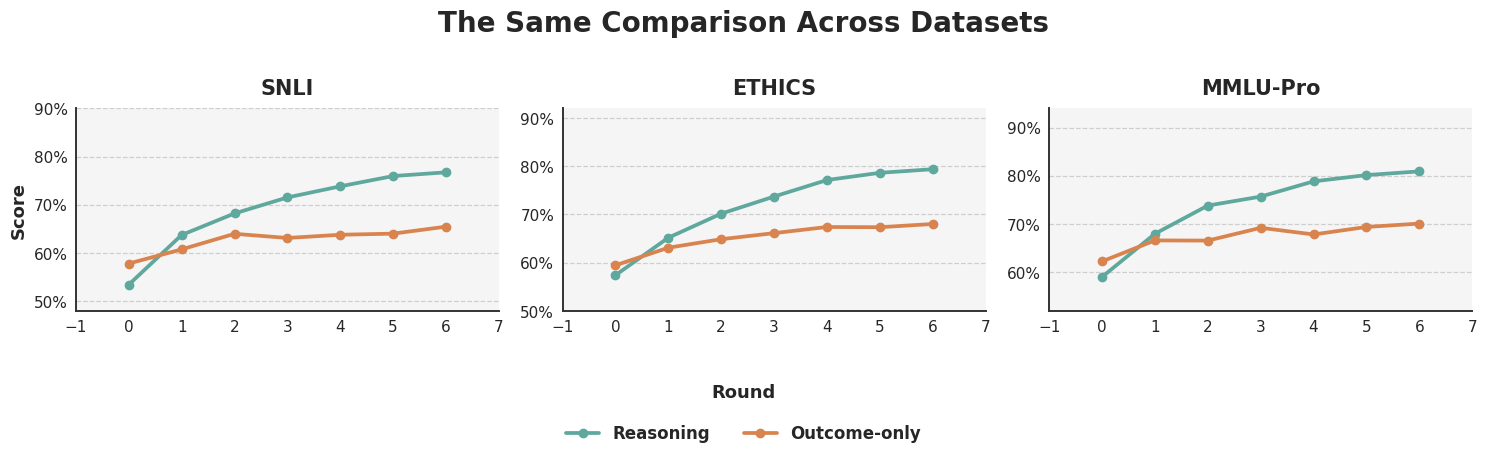

In [91]:
# Faceted line charts with a shared legend and common x-label
facet_fig, facet_axes = plot_facets(
    facet_df,
    facet="dataset", x="round", y="value", series="series",
    ncols=3, title="The Same Comparison Across Datasets",
    xlabel="Round", ylabel="Score",
    ylims=[(48, 90), (50, 92), (52, 94)],
)
plt.show()

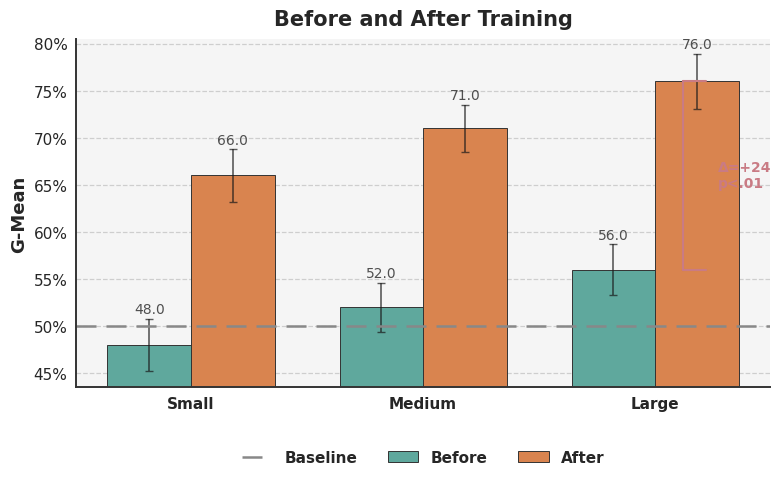

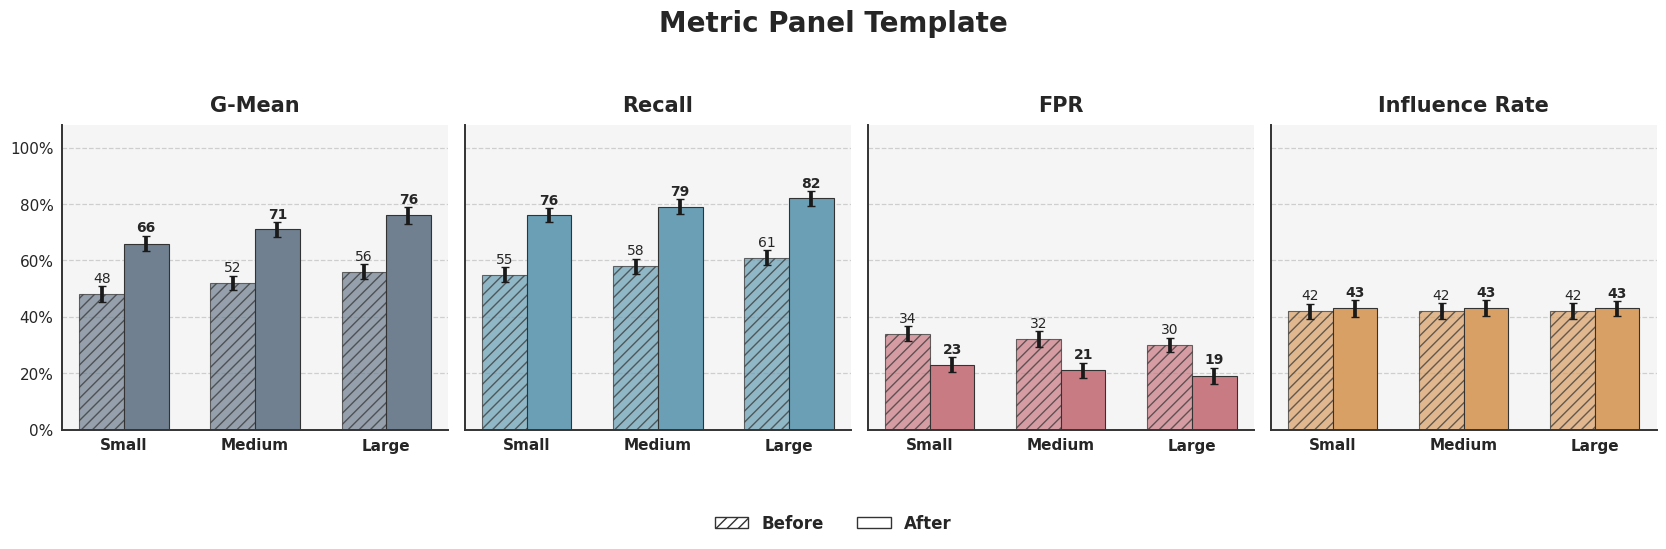

In [92]:
# Grouped bars with uncertainty, baseline, and a final-category delta bracket
gmean_df = bar_df[bar_df["metric"] == "G-Mean"]
fig, ax = plt.subplots(figsize=(8, 5))
plot_grouped_bars(
    gmean_df,
    category="experiment", group="state", value="value", error="error",
    title="Before and After Training", ylabel="G-Mean", baseline=0.50, ax=ax,
)
large_values = gmean_df[gmean_df["experiment"] == "Large"].set_index("state")["value"] * 100
add_delta_bracket(ax, 2, large_values["After"], large_values["Before"], text="Δ=+24\np<.01")
fig.tight_layout()
plt.show()

# One panel per metric; hatching carries state while color carries metric identity
panel_fig, panel_axes = plot_metric_panels(
    bar_df,
    title="Metric Panel Template",
)
plt.show()

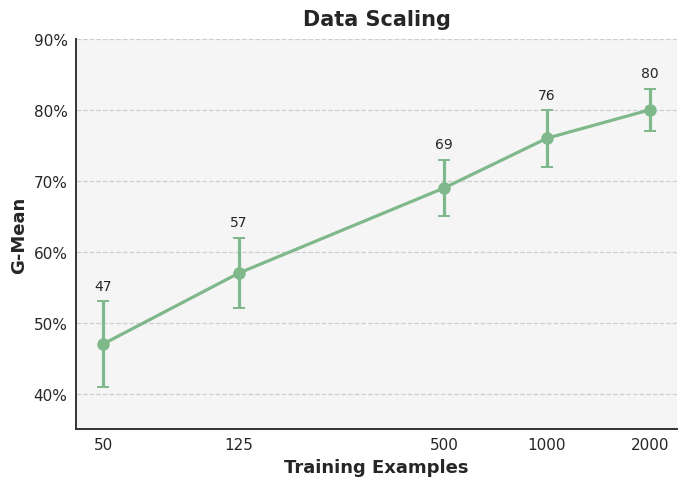

In [93]:
# Data-scaling curve: log x-axis, nominal ticks, and asymmetric error bars
fig, ax = plt.subplots(figsize=(7, 5))
x_values = scaling_df["training_examples"].to_numpy()
y_values = scaling_df["mean"].to_numpy() * 100
low = scaling_df["ci_low"].to_numpy() * 100
high = scaling_df["ci_high"].to_numpy() * 100
ax.errorbar(
    x_values, y_values, yerr=[y_values - low, high - y_values],
    color=COLORS["green"], marker="o", markersize=8,
    linewidth=2.3, capsize=4, capthick=1.4,
)
for x_value, y_value, high_value in zip(x_values, y_values, high):
    ax.annotate(f"{y_value:.0f}", (x_value, high_value), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=FONT["annotation"])
ax.set_xscale("log")
ax.set_xticks(x_values, [str(value) for value in x_values])
ax.xaxis.set_minor_locator(plt.NullLocator())
style_axis(ax, title="Data Scaling", xlabel="Training Examples", ylabel="G-Mean", ylim=(35, 90), percent_y=True)
fig.tight_layout()
plt.show()

## 14. Validate Plotting Helpers

Run this after changing the helpers. It checks common failure modes and writes a small reference export to `style_guide_figures/`.

### Quick usage checklist

- Put data in tidy form: one observation per row.
- Scale rates to percentages at plot time, not in stored data.
- Use no more than five categorical colors in one figure.
- Prefer one shared legend for facets.
- Show uncertainty when it changes interpretation.
- Annotate only the comparison the caption discusses.
- Export both PDF and PNG from the final figure object.

In [94]:
def assert_raises(expected_exception, function, *args, **kwargs):
    try:
        function(*args, **kwargs)
    except expected_exception:
        return
    raise AssertionError(f"Expected {expected_exception.__name__}")


# Data-contract failures are explicit.
assert_raises(ValueError, require_columns, pd.DataFrame({"x": [1]}), ["x", "y"])
assert_raises(ValueError, require_columns, pd.DataFrame(columns=["x"]), ["x"])
invalid_legend_fig = plt.figure()
assert_raises(ValueError, add_shared_legend, invalid_legend_fig, [], [], location="above")
plt.close(invalid_legend_fig)
assert_raises(
    ValueError,
    plot_lines,
    line_df,
    x="round", y="mean", series="series",
    ci_low="ci_low", ci_high="ci_high", ci_style="invalid",
)

# Returned objects expose expected labels and legend entries.
validation_fig, validation_ax = plt.subplots(figsize=(6, 4))
plot_lines(
    line_df[line_df["series"] != "Reference model"],
    x="round", y="mean", series="series",
    ci_low="ci_low", ci_high="ci_high", ci_style="ribbon",
    title="Validation Reference", xlabel="Round", ylabel="Score", ax=validation_ax,
)
assert isinstance(validation_fig, plt.Figure)
assert validation_ax.get_xlabel() == "Round"
assert validation_ax.get_ylabel() == "Score"
legend_labels = [text.get_text() for text in validation_ax.get_legend().get_texts()]
assert legend_labels == ["Reasoning", "Outcome-only"]

# Export paths exist and use the requested formats.
export_paths = save_figure(validation_fig, "validation_reference")
assert {path.suffix for path in export_paths} == {".pdf", ".png"}
assert all(path.exists() and path.stat().st_size > 0 for path in export_paths)
plt.close(validation_fig)

print("All plotting helper checks passed.")
print("Exports:", *(str(path) for path in export_paths), sep="\n- ")

All plotting helper checks passed.
Exports:
- style_guide_figures/validation_reference.pdf
- style_guide_figures/validation_reference.png


# Competition

Side-by-side lie-detection monitor performance under the earlier non-blinded evaluation and the new blinded competition evaluation.

The previous results compare black-box and aggregate white-box monitor performance. The competition results use the same comparison under blinded evaluation.

In [ ]:
competition_df = pd.DataFrame({
    "results": [
        "Previous Results\n(Non-Blinded)",
        "Previous Results\n(Non-Blinded)",
        "Competition Results\n(Blinded)",
        "Competition Results\n(Blinded)",
    ],
    "monitor": ["Black-box Monitor", "White-box Monitor"] * 2,
    "auroc": [0.879, 0.941, 0.61, 0.84],
}) 
# 0.833 for Flai-Chai whitebox excluding the FAR model, .67 including it
# 0.7541 for Flai-Chai blackbox excluding the FAR model, .61 including it

competition_df

,results,monitor,auroc
0,Previous Results\n(Non-Blinded),Black-box Monitor,0.879
1,Previous Results\n(Non-Blinded),White-box Monitor,0.941
2,Competition Results\n(Blinded),Black-box Monitor,0.610
3,Competition Results\n(Blinded),White-box Monitor,0.840


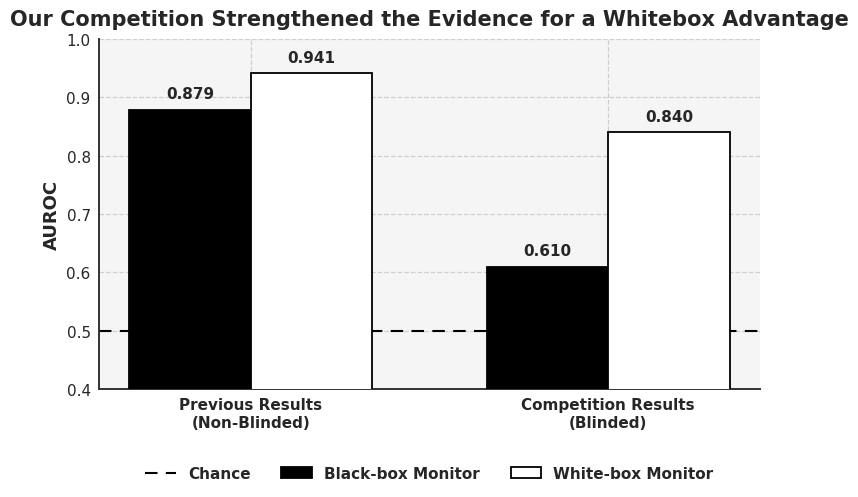

Saved:
- style_guide_figures/competition_blackbox_vs_whitebox.pdf
- style_guide_figures/competition_blackbox_vs_whitebox.png


In [96]:
# Black-box vs. white-box lie-detection performance
result_order = ["Previous Results\n(Non-Blinded)", "Competition Results\n(Blinded)"]
monitor_order = ["Black-box Monitor", "White-box Monitor"]
x_positions = np.arange(len(result_order))
bar_width = 0.34

fig, ax = plt.subplots(figsize=(7.5, 5.2))

for monitor_index, monitor_name in enumerate(monitor_order):
    monitor_df = competition_df[competition_df["monitor"] == monitor_name].set_index("results").reindex(result_order)
    values = monitor_df["auroc"].to_numpy()
    offset = (monitor_index - 0.5) * bar_width
    bars = ax.bar(
        x_positions + offset,
        values,
        bar_width,
        label=monitor_name,
        color="black" if monitor_name == "Black-box Monitor" else "white",
        edgecolor="black",
        linewidth=1.3,
        zorder=3,
    )
    for bar, value in zip(bars, values):
        ax.annotate(
            f"{value:.3f}",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=FONT["annotation"] + 1,
            fontweight="bold",
        )

ax.axhline(0.5, color="black", linestyle=(0, (6, 4)), linewidth=1.5,
           label="Chance", zorder=2)
ax.set_xticks(x_positions, result_order, fontweight="bold")
style_axis(
    ax,
    # title="Lie-Detection Monitor Performance",
    title="Our Competition Strengthened the Evidence for a Whitebox Advantage",
    ylabel="AUROC",
    ylim=(0.4, 1.0),
)
ax.grid(True, axis="both", linestyle="--", color=GRID_COLOR,
        linewidth=GRID_LINEWIDTH, alpha=GRID_ALPHA)
ax.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    prop={"size": 11, "weight": "bold"},
)
fig.tight_layout()

competition_export_paths = save_figure(fig, "competition_blackbox_vs_whitebox")
plt.show()

print("Saved:", *(str(path) for path in competition_export_paths), sep="\n- ")